# Análise da Simulação SWGO — Múon de 5 GeV no WCD
**Dissertação de Mestrado em Física**

Simulação Geant4 11.1.3 — Múon vertical de 5 GeV  
Detector: WCD cilíndrico (r=170 cm, h=187.87 cm) com revestimento Tyvek  
4 PMTs (3 no fundo em triângulo equilátero + 1 no topo)

---

## 1. Importações e Configurações

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from scipy.stats import norm, poisson
from scipy.optimize import curve_fit
from scipy.special import factorial

# Estilo
sns.set_theme(style='whitegrid', palette='pastel')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# Funções de ajuste
def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma)**2)

def landau_approx(x, A, mu, sigma):
    """Aproximação da distribuição de Landau via gaussiana assimétrica"""
    z = (x - mu) / sigma
    return A * np.exp(-0.5 * (z + np.exp(-z)))

def fit_and_plot(ax, data, bins, color, fit_func='gaussian', label=''):
    """Plota histograma com ajuste e parâmetros na caixa de texto"""
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]
    
    ax.bar(centers, counts, width=width*0.9, color=color, alpha=0.7, label='Simulação')
    
    # Ajuste
    try:
        if fit_func == 'gaussian':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, gaussian(x_fit, *popt), 'r-', linewidth=2, label='Ajuste Gaussiano')
            textstr = (
                f'Ajuste Gaussiano\n'
                f'$\\mu$ = {popt[1]:.2f} ± {perr[1]:.2f}\n'
                f'$\\sigma$ = {abs(popt[2]):.2f} ± {perr[2]:.2f}\n'
                f'N = {len(data)}'
            )
        elif fit_func == 'landau':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(landau_approx, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, landau_approx(x_fit, *popt), 'r-', linewidth=2, label='Ajuste Landau')
            textstr = (
                f'Ajuste Landau\n'
                f'MPV = {popt[1]:.2f} ± {perr[1]:.2f} MeV\n'
                f'$\\sigma$ = {abs(popt[2]):.2f} ± {perr[2]:.2f} MeV\n'
                f'N = {len(data)}'
            )
        
        props = dict(boxstyle='round', facecolor='white', alpha=0.8)
        ax.text(0.97, 0.97, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment='right', bbox=props)
    except Exception as e:
        print(f'Ajuste falhou: {e}')
    
    return ax

print('Bibliotecas carregadas!')

Bibliotecas carregadas!


## 2. Carregamento dos Dados

In [2]:
# Caminhos dos arquivos
DATA_PATH = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_Data.csv'
PMT_PATH  = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_PMTData.csv'

df = pd.read_csv(DATA_PATH, comment='#', header=None, names=[
    'iEventID', 'EnergyDeposited_MeV', 'PositionX_cm', 'PositionY_cm',
    'PositionZ_cm', 'Time_ns', 'EnergyElectronSec_MeV', 'nElectronSec',
    'nCerenkovByMuon', 'nCerenkovByElectron', 'EdepGammas_MeV', 'EdepTrack_MeV'
])

df_pmt = pd.read_csv(PMT_PATH, comment='#', header=None, names=[
    'iEventID', 'nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3', 'nFotonsPMT4'
])

# Total de fótons detectados
df_pmt['nFotonsTotal'] = df_pmt['nFotonsPMT1'] + df_pmt['nFotonsPMT2'] + df_pmt['nFotonsPMT3']

# Merge
df_all = df.merge(df_pmt, on='iEventID')

# Total de fótons Cherenkov produzidos
df_all['nCerenkovTotal'] = df_all['nCerenkovByMuon'] + df_all['nCerenkovByElectron']

print(f'Eventos carregados: {len(df)}')
print(f'\nEstatísticas básicas:')
df[['EnergyDeposited_MeV', 'nCerenkovByMuon', 'nCerenkovByElectron', 'nElectronSec']].describe().round(2)

Eventos carregados: 1000

Estatísticas básicas:


,EnergyDeposited_MeV,nCerenkovByMuon,nCerenkovByElectron,nElectronSec
count,1000.00,1000.00,1000.00,1000.00
mean,396.78,60886.62,11517.37,42.17
std,67.10,246.80,6990.39,6.34
min,319.51,60075.00,2185.00,24.00
25%,358.25,60721.75,6740.25,38.00
50%,378.40,60888.50,9539.00,42.00
75%,413.34,61054.00,14760.25,46.00
max,1112.56,61784.00,65504.00,63.00


## 3. Energia Depositada — Distribuição de Landau

O múon de 5 GeV é uma **partícula mínimamente ionizante (MIP)** na água.  
A distribuição de energia depositada segue uma distribuição de **Landau** —  
assimétrica com cauda para altos valores, característica de partículas relativísticas.

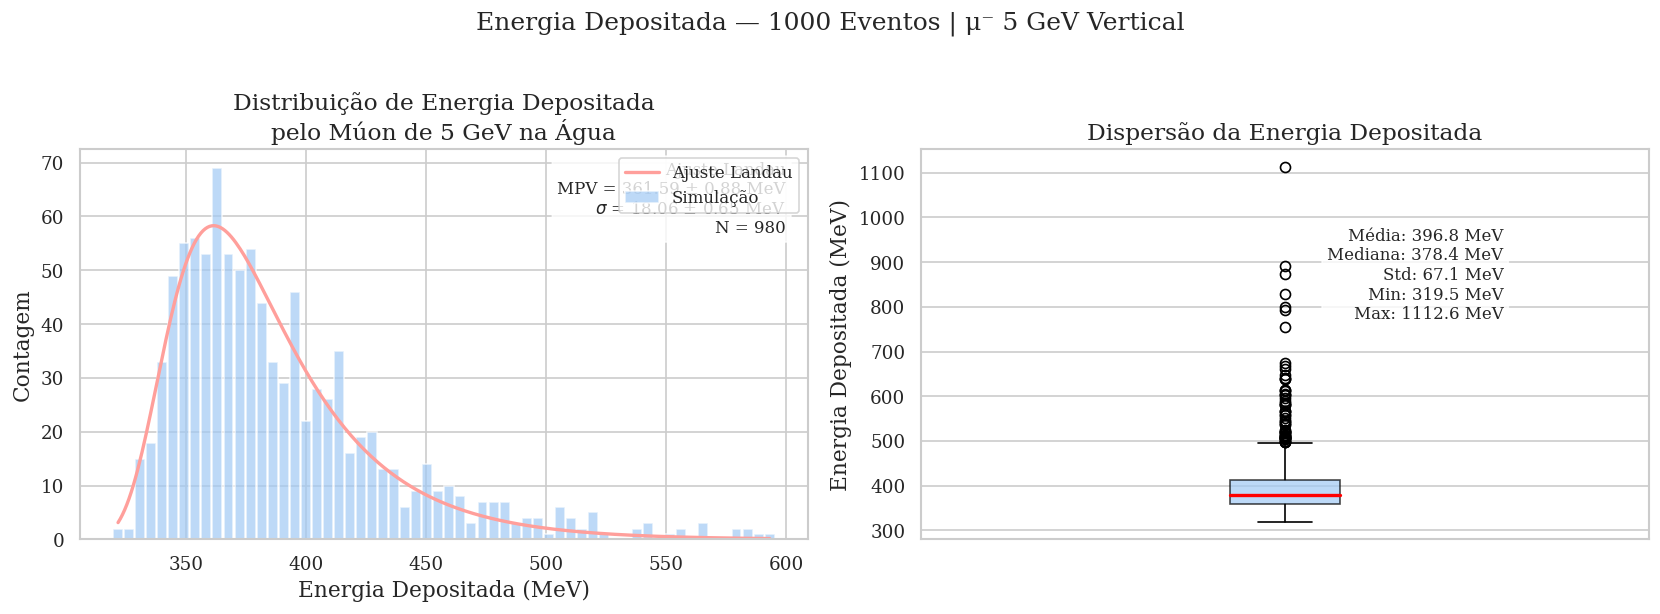

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# Filtra outliers (>3 sigma) para o ajuste
edep = df['EnergyDeposited_MeV']
edep_filtered = edep[edep < edep.mean() + 3*edep.std()]

ax1 = axes[0]
fit_and_plot(ax1, edep_filtered, bins=60, color=palette[0], fit_func='landau')
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Contagem')
ax1.set_title('Distribuição de Energia Depositada\npelo Múon de 5 GeV na Água')
ax1.legend(fontsize=10)

# Boxplot
ax2 = axes[1]
bp = ax2.boxplot(edep, patch_artist=True,
                 boxprops=dict(facecolor=palette[0], alpha=0.7),
                 medianprops=dict(color='red', linewidth=2))
ax2.set_ylabel('Energia Depositada (MeV)')
ax2.set_title('Dispersão da Energia Depositada')
ax2.set_xticks([])
textstr = (
    f'Média: {edep.mean():.1f} MeV\n'
    f'Mediana: {edep.median():.1f} MeV\n'
    f'Std: {edep.std():.1f} MeV\n'
    f'Min: {edep.min():.1f} MeV\n'
    f'Max: {edep.max():.1f} MeV'
)
props = dict(boxstyle='round', facecolor='white', alpha=0.8)
ax2.text(0.97, 0.97, textstr, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right', bbox=props)

plt.suptitle('Energia Depositada — 1000 Eventos | μ⁻ 5 GeV Vertical', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('energia_depositada.png')
plt.show()

## 4. Fótons Cherenkov Produzidos

Distribuição do número de fótons Cherenkov produzidos pelo múon e pelos elétrons delta.

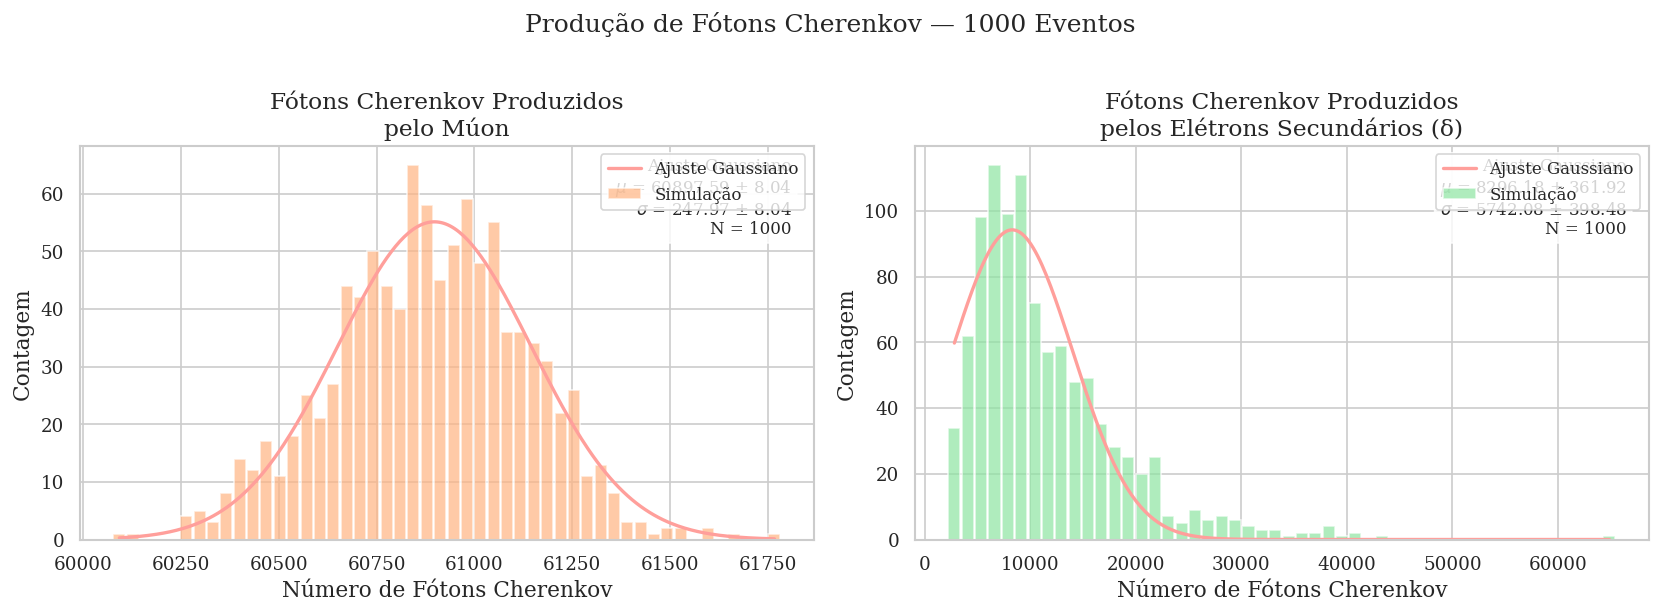

Fótons pelo múon:     60887 ± 247
Fótons por elétrons:  11517 ± 6990
Fração por elétrons:  15.9%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

ax1 = axes[0]
fit_and_plot(ax1, df['nCerenkovByMuon'], bins=50, color=palette[1], fit_func='gaussian')
ax1.set_xlabel('Número de Fótons Cherenkov')
ax1.set_ylabel('Contagem')
ax1.set_title('Fótons Cherenkov Produzidos\npelo Múon')
ax1.legend(fontsize=10)

ax2 = axes[1]
fit_and_plot(ax2, df['nCerenkovByElectron'], bins=50, color=palette[2], fit_func='gaussian')
ax2.set_xlabel('Número de Fótons Cherenkov')
ax2.set_ylabel('Contagem')
ax2.set_title('Fótons Cherenkov Produzidos\npelos Elétrons Secundários (δ)')
ax2.legend(fontsize=10)

plt.suptitle('Produção de Fótons Cherenkov — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('cerenkov_producao.png')
plt.show()

total = df['nCerenkovByMuon'] + df['nCerenkovByElectron']
fracao = df['nCerenkovByElectron'].mean() / total.mean() * 100
print(f'Fótons pelo múon:     {df["nCerenkovByMuon"].mean():.0f} ± {df["nCerenkovByMuon"].std():.0f}')
print(f'Fótons por elétrons:  {df["nCerenkovByElectron"].mean():.0f} ± {df["nCerenkovByElectron"].std():.0f}')
print(f'Fração por elétrons:  {fracao:.1f}%')

## 5. Fótons Detectados pelas PMTs

Distribuição de fótons Cherenkov detectados por cada PMT após aplicação da eficiência quântica.

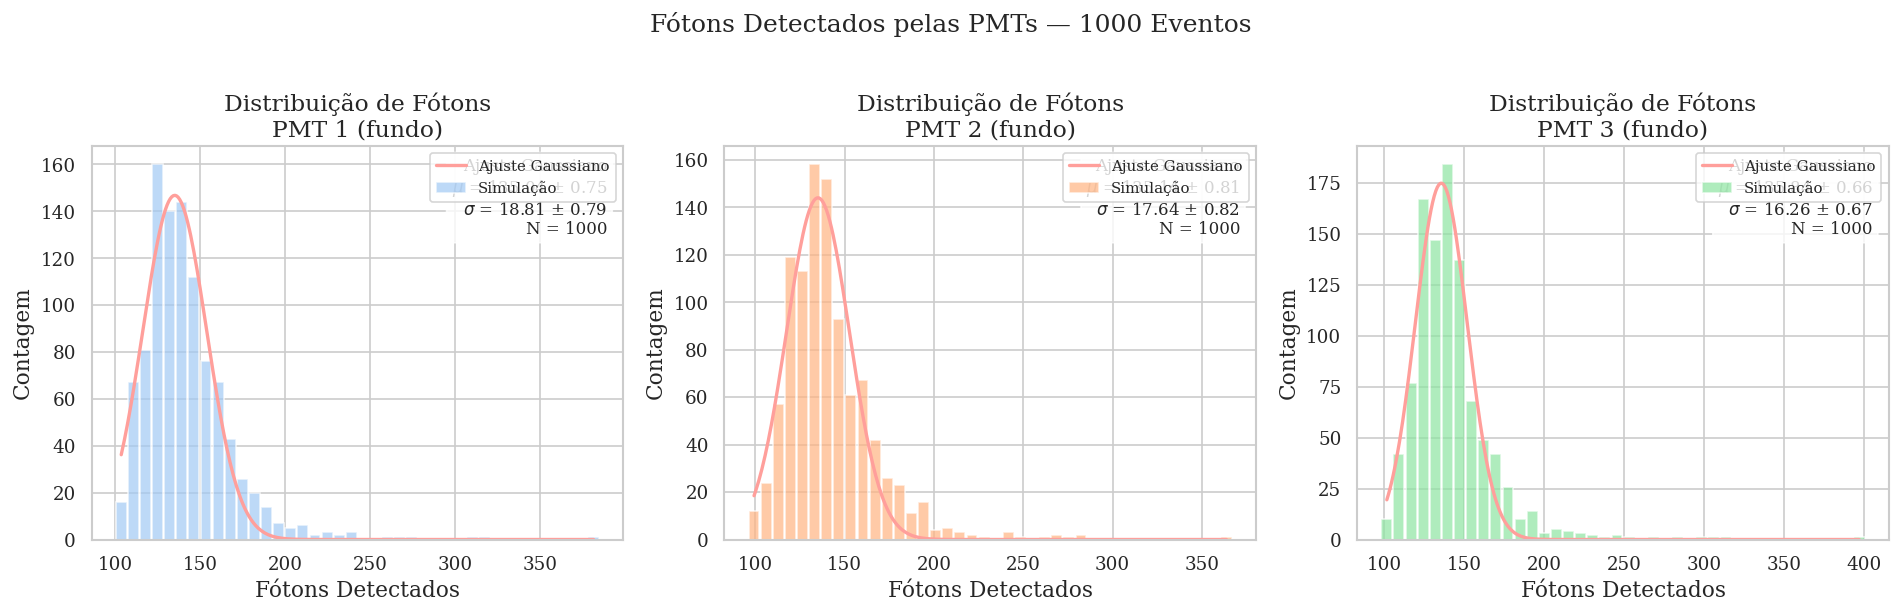

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette = sns.color_palette('pastel')
pmts = ['nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3']
labels = ['PMT 1 (fundo)', 'PMT 2 (fundo)', 'PMT 3 (fundo)']
colors = [palette[0], palette[1], palette[2]]

for ax, col, label, color in zip(axes, pmts, labels, colors):
    fit_and_plot(ax, df_pmt[col], bins=40, color=color, fit_func='gaussian')
    ax.set_xlabel('Fótons Detectados')
    ax.set_ylabel('Contagem')
    ax.set_title(f'Distribuição de Fótons\n{label}')
    ax.legend(fontsize=9)

plt.suptitle('Fótons Detectados pelas PMTs — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('pmt_distribuicoes.png')
plt.show()

## 6. Comparação entre PMTs

Comparação da resposta das três PMTs do fundo — para um múon vertical central,
esperamos distribuições similares entre as PMTs (simetria azimutal).

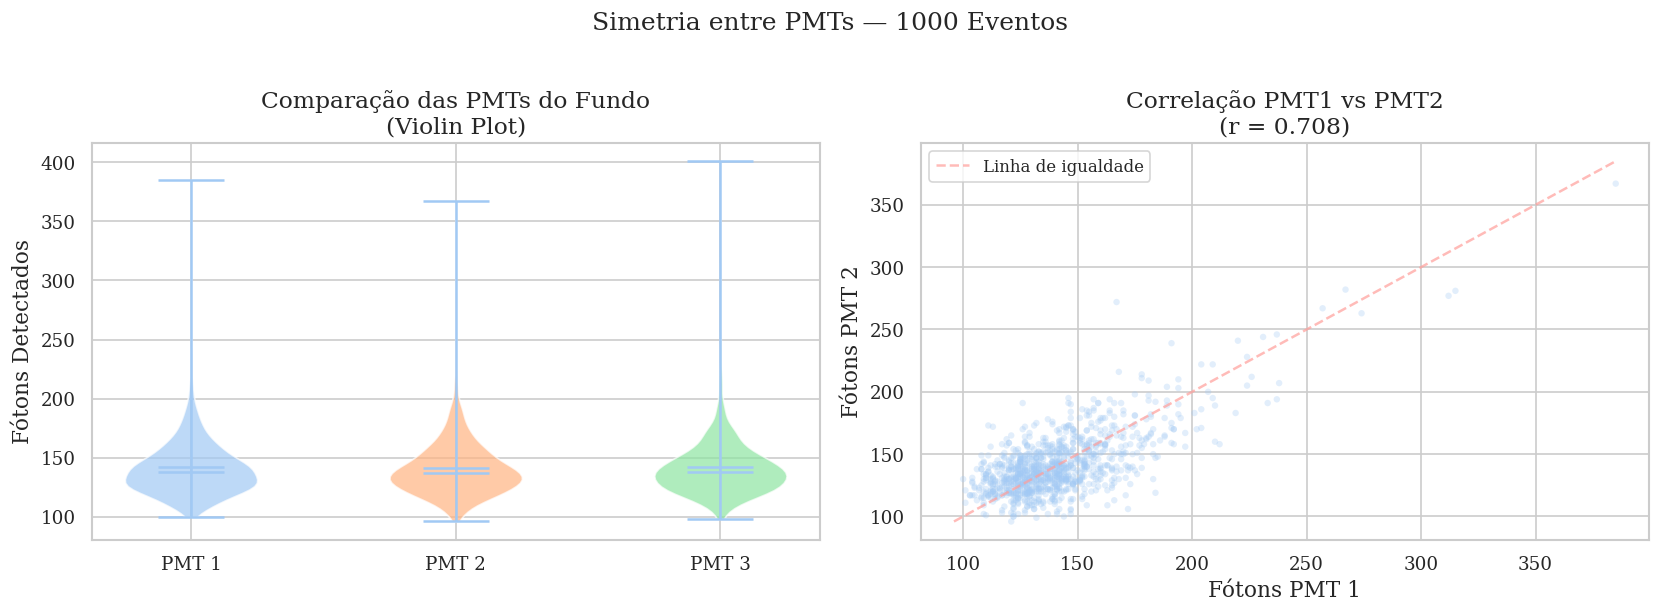

Médias por PMT:
  nFotonsPMT1: 141.8 ± 25.6
  nFotonsPMT2: 141.7 ± 25.4
  nFotonsPMT3: 141.9 ± 25.4


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# Violin plot comparativo
ax1 = axes[0]
data_violin = [df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'], df_pmt['nFotonsPMT3']]
vp = ax1.violinplot(data_violin, positions=[1, 2, 3], showmeans=True, showmedians=True)
for i, pc in enumerate(vp['bodies']):
    pc.set_facecolor(palette[i])
    pc.set_alpha(0.7)
ax1.set_xticks([1, 2, 3])
ax1.set_xticklabels(['PMT 1', 'PMT 2', 'PMT 3'])
ax1.set_ylabel('Fótons Detectados')
ax1.set_title('Comparação das PMTs do Fundo\n(Violin Plot)')

# Correlação PMT1 vs PMT2
ax2 = axes[1]
ax2.scatter(df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'],
            alpha=0.3, s=15, color=palette[0], edgecolors='none')
# Linha diagonal
lim = [min(df_pmt['nFotonsPMT1'].min(), df_pmt['nFotonsPMT2'].min()),
       max(df_pmt['nFotonsPMT1'].max(), df_pmt['nFotonsPMT2'].max())]
ax2.plot(lim, lim, 'r--', linewidth=1.5, alpha=0.7, label='Linha de igualdade')
corr = df_pmt['nFotonsPMT1'].corr(df_pmt['nFotonsPMT2'])
ax2.set_xlabel('Fótons PMT 1')
ax2.set_ylabel('Fótons PMT 2')
ax2.set_title(f'Correlação PMT1 vs PMT2\n(r = {corr:.3f})')
ax2.legend(fontsize=10)

plt.suptitle('Simetria entre PMTs — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('pmt_comparacao.png')
plt.show()

print('Médias por PMT:')
for col in ['nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3']:
    print(f'  {col}: {df_pmt[col].mean():.1f} ± {df_pmt[col].std():.1f}')

## 7. Eficiência de Detecção

Comparação entre fótons produzidos (Cherenkov) e fótons detectados pelas PMTs.

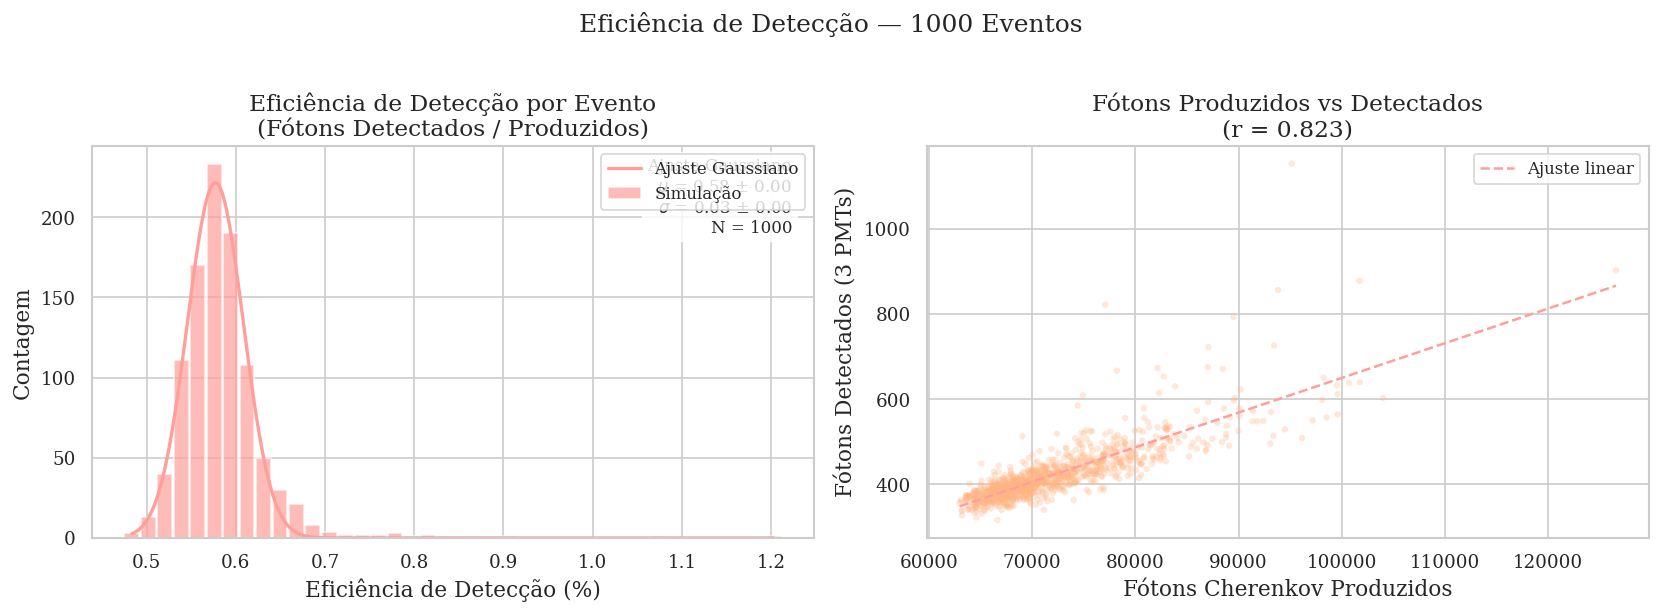

Eficiência média: 0.59% ± 0.05%
Total produzido (média): 72404
Total detectado (média): 425


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# Eficiência por evento
df_all['eficiencia'] = df_all['nFotonsTotal'] / df_all['nCerenkovTotal'] * 100

ax1 = axes[0]
fit_and_plot(ax1, df_all['eficiencia'], bins=40, color=palette[3], fit_func='gaussian')
ax1.set_xlabel('Eficiência de Detecção (%)')
ax1.set_ylabel('Contagem')
ax1.set_title('Eficiência de Detecção por Evento\n(Fótons Detectados / Produzidos)')
ax1.legend(fontsize=10)

# Correlação produzidos vs detectados
ax2 = axes[1]
ax2.scatter(df_all['nCerenkovTotal'], df_all['nFotonsTotal'],
            alpha=0.3, s=15, color=palette[1], edgecolors='none')
z = np.polyfit(df_all['nCerenkovTotal'], df_all['nFotonsTotal'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_all['nCerenkovTotal'].min(), df_all['nCerenkovTotal'].max(), 100)
ax2.plot(x_line, p(x_line), 'r--', linewidth=1.5, label=f'Ajuste linear')
corr = df_all['nCerenkovTotal'].corr(df_all['nFotonsTotal'])
ax2.set_xlabel('Fótons Cherenkov Produzidos')
ax2.set_ylabel('Fótons Detectados (3 PMTs)')
ax2.set_title(f'Fótons Produzidos vs Detectados\n(r = {corr:.3f})')
ax2.legend(fontsize=10)

plt.suptitle('Eficiência de Detecção — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('eficiencia_deteccao.png')
plt.show()

print(f'Eficiência média: {df_all["eficiencia"].mean():.2f}% ± {df_all["eficiencia"].std():.2f}%')
print(f'Total produzido (média): {df_all["nCerenkovTotal"].mean():.0f}')
print(f'Total detectado (média): {df_all["nFotonsTotal"].mean():.0f}')

## 8. Elétrons Secundários (Raios Delta)

Distribuição do número de elétrons delta produzidos por ionização muônica.

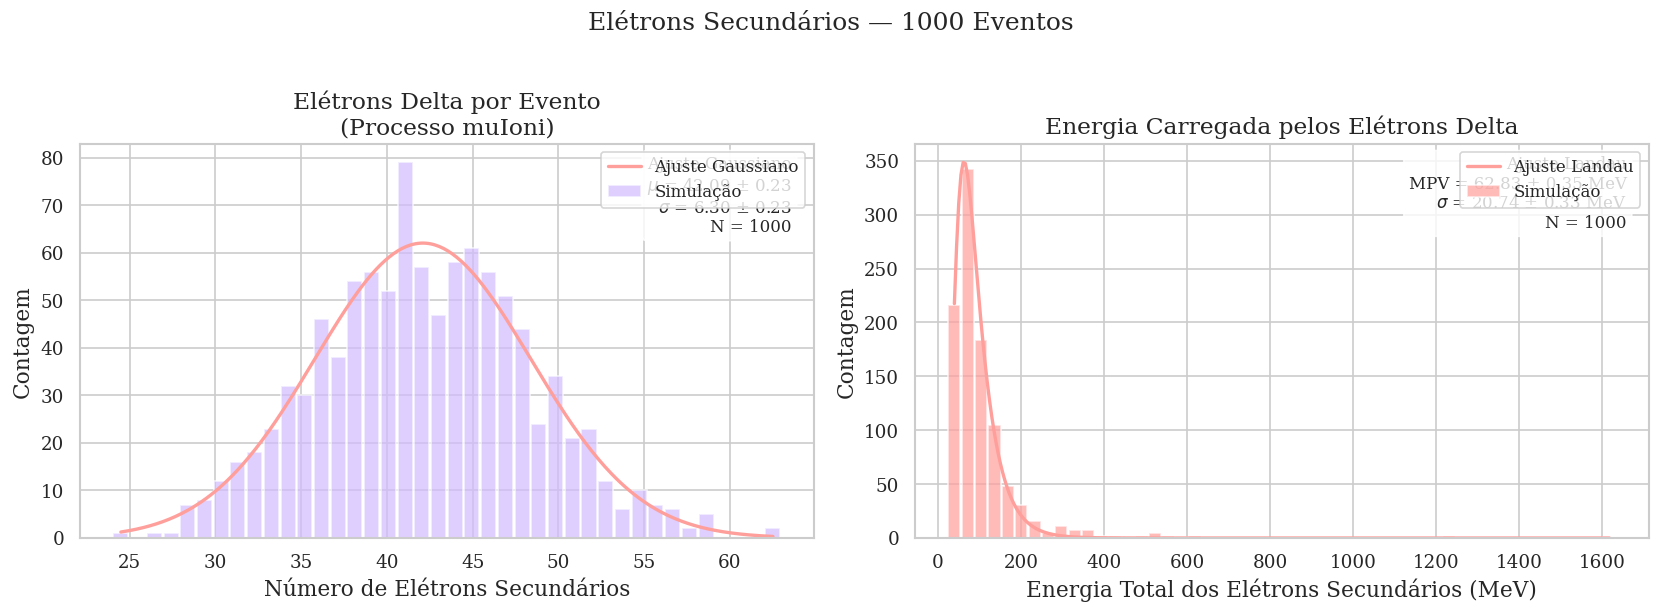

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

ax1 = axes[0]
fit_and_plot(ax1, df['nElectronSec'], bins=40, color=palette[4], fit_func='gaussian')
ax1.set_xlabel('Número de Elétrons Secundários')
ax1.set_ylabel('Contagem')
ax1.set_title('Elétrons Delta por Evento\n(Processo muIoni)')
ax1.legend(fontsize=10)

ax2 = axes[1]
fit_and_plot(ax2, df['EnergyElectronSec_MeV'], bins=50, color=palette[3], fit_func='landau')
ax2.set_xlabel('Energia Total dos Elétrons Secundários (MeV)')
ax2.set_ylabel('Contagem')
ax2.set_title('Energia Carregada pelos Elétrons Delta')
ax2.legend(fontsize=10)

plt.suptitle('Elétrons Secundários — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('eletrons_secundarios.png')
plt.show()

## 9. Correlações Físicas

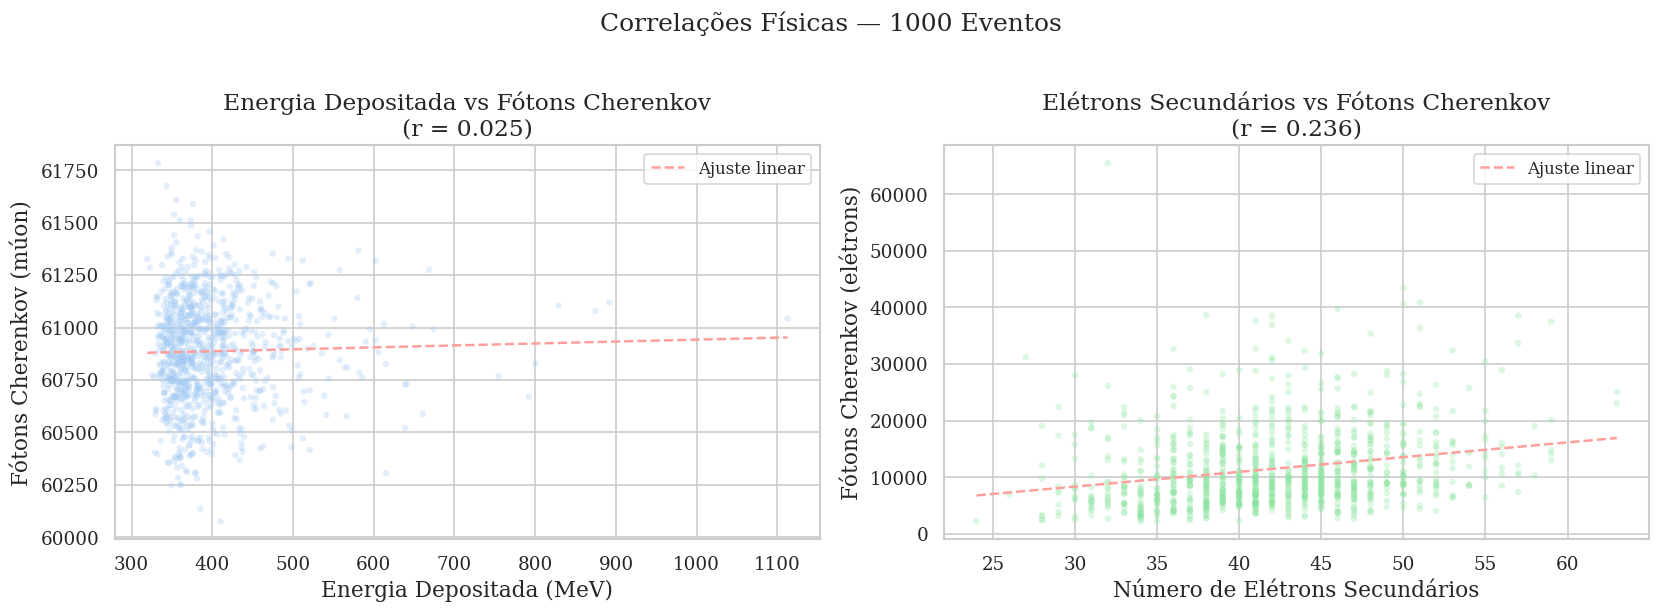

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# Energia depositada vs fótons Cherenkov do múon
ax1 = axes[0]
ax1.scatter(df['EnergyDeposited_MeV'], df['nCerenkovByMuon'],
            alpha=0.3, s=15, color=palette[0], edgecolors='none')
z = np.polyfit(df['EnergyDeposited_MeV'], df['nCerenkovByMuon'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['EnergyDeposited_MeV'].min(), df['EnergyDeposited_MeV'].max(), 100)
ax1.plot(x_line, p(x_line), 'r--', linewidth=1.5, label='Ajuste linear')
corr1 = df['EnergyDeposited_MeV'].corr(df['nCerenkovByMuon'])
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Fótons Cherenkov (múon)')
ax1.set_title(f'Energia Depositada vs Fótons Cherenkov\n(r = {corr1:.3f})')
ax1.legend(fontsize=10)

# Elétrons secundários vs Cherenkov por elétrons
ax2 = axes[1]
ax2.scatter(df['nElectronSec'], df['nCerenkovByElectron'],
            alpha=0.3, s=15, color=palette[2], edgecolors='none')
z2 = np.polyfit(df['nElectronSec'], df['nCerenkovByElectron'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(df['nElectronSec'].min(), df['nElectronSec'].max(), 100)
ax2.plot(x_line2, p2(x_line2), 'r--', linewidth=1.5, label='Ajuste linear')
corr2 = df['nElectronSec'].corr(df['nCerenkovByElectron'])
ax2.set_xlabel('Número de Elétrons Secundários')
ax2.set_ylabel('Fótons Cherenkov (elétrons)')
ax2.set_title(f'Elétrons Secundários vs Fótons Cherenkov\n(r = {corr2:.3f})')
ax2.legend(fontsize=10)

plt.suptitle('Correlações Físicas — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('correlacoes.png')
plt.show()

## 10. Resumo Físico da Simulação

In [11]:
resumo = pd.DataFrame({
    'Grandeza': [
        'Energia depositada (MeV)',
        'Fótons Cherenkov (múon)',
        'Fótons Cherenkov (elétrons)',
        'Total fótons Cherenkov produzidos',
        'Fração por elétrons (%)',
        'Elétrons secundários (N)',
        'Energia elétrons sec. (MeV)',
        'Fótons detectados PMT1',
        'Fótons detectados PMT2',
        'Fótons detectados PMT3',
        'Total detectado (3 PMTs)',
        'Eficiência de detecção (%)',
        'Deposição por gammas (MeV)',
    ],
    'Média': [
        df['EnergyDeposited_MeV'].mean(),
        df['nCerenkovByMuon'].mean(),
        df['nCerenkovByElectron'].mean(),
        df_all['nCerenkovTotal'].mean(),
        df['nCerenkovByElectron'].mean() / (df['nCerenkovByMuon'] + df['nCerenkovByElectron']).mean() * 100,
        df['nElectronSec'].mean(),
        df['EnergyElectronSec_MeV'].mean(),
        df_pmt['nFotonsPMT1'].mean(),
        df_pmt['nFotonsPMT2'].mean(),
        df_pmt['nFotonsPMT3'].mean(),
        df_pmt['nFotonsTotal'].mean(),
        df_all['eficiencia'].mean(),
        df['EdepGammas_MeV'].mean(),
    ],
    'Desvio Padrão': [
        df['EnergyDeposited_MeV'].std(),
        df['nCerenkovByMuon'].std(),
        df['nCerenkovByElectron'].std(),
        df_all['nCerenkovTotal'].std(),
        None,
        df['nElectronSec'].std(),
        df['EnergyElectronSec_MeV'].std(),
        df_pmt['nFotonsPMT1'].std(),
        df_pmt['nFotonsPMT2'].std(),
        df_pmt['nFotonsPMT3'].std(),
        df_pmt['nFotonsTotal'].std(),
        df_all['eficiencia'].std(),
        df['EdepGammas_MeV'].std(),
    ]
})

resumo = resumo.round(3)
print('=' * 60)
print('RESUMO FÍSICO DA SIMULAÇÃO SWGO')
print(f'Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical')
print(f'Detector: WCD | Água: r=170cm, h=187.87cm | Tyvek')
print(f'Eventos simulados: {len(df)}')
print('=' * 60)
print(resumo.to_string(index=False))

RESUMO FÍSICO DA SIMULAÇÃO SWGO
Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical
Detector: WCD | Água: r=170cm, h=187.87cm | Tyvek
Eventos simulados: 1000
                         Grandeza     Média  Desvio Padrão
         Energia depositada (MeV)   396.780         67.097
          Fótons Cherenkov (múon) 60886.617        246.797
      Fótons Cherenkov (elétrons) 11517.370       6990.394
Total fótons Cherenkov produzidos 72403.987       7001.341
          Fração por elétrons (%)    15.907            NaN
         Elétrons secundários (N)    42.172          6.336
      Energia elétrons sec. (MeV)   112.838        122.709
           Fótons detectados PMT1   141.789         25.606
           Fótons detectados PMT2   141.682         25.415
           Fótons detectados PMT3   141.923         25.432
         Total detectado (3 PMTs)   425.394         69.190
       Eficiência de detecção (%)     0.586          0.052
       Deposição por gammas (MeV)     0.054          0.083
